# Problem 1: Smart Home Energy Consumption (Bayesian Network)

Group members:
1.
2.
3.

In [2]:
!pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 48.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pgmpy]


In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

try:
    from pgmpy.models import DiscreteBayesianNetwork as BayesNet
except ImportError:
    from pgmpy.models import BayesianNetwork as BayesNet

from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.estimators import MaximumLikelihoodEstimator, BayesianEstimator

## Part A: Expert network

In [4]:
edges = [("Weather", "AC"),
          ("DayType", "Occupancy"),
         ("Occupancy", "AC"),
           ("Occupancy", "ApplianceLoad"),
         ("AC", "Energy"),
         ("ApplianceLoad", "Energy")]

model = BayesNet(edges)

states = {"Weather": ["Hot", "Mild", "Cold"],
          "DayType": ["Weekday", "Weekend"],
          "Occupancy": ["High", "Low"],
          "AC": ["On", "Off"],
          "ApplianceLoad": ["Heavy", "Light"],
          "Energy": ["High", "Low"]}

cpdW = TabularCPD("Weather", 3, [[0.5], [0.3], [0.2]],
                  state_names={"Weather": states["Weather"]})
cpdD = TabularCPD("DayType", 2, [[0.7], [0.3]],
                  state_names={"DayType": states["DayType"]})
cpdO = TabularCPD("Occupancy", 2, [[0.45, 0.80], [0.55, 0.20]],
                  evidence=["DayType"], evidence_card=[2],
                  state_names={"Occupancy": states["Occupancy"], "DayType": states["DayType"]})
cpdA = TabularCPD("AC", 2,
                  [[0.90, 0.60, 0.40, 0.15, 0.10, 0.05],
                   [0.10, 0.40, 0.60, 0.85, 0.90, 0.95]],
                  evidence=["Weather", "Occupancy"], evidence_card=[3, 2],
                  state_names={"AC": states["AC"], "Weather": states["Weather"],
                               "Occupancy": states["Occupancy"]})

cpdL = TabularCPD("ApplianceLoad", 2, [[0.75, 0.35], [0.25, 0.65]],
                  evidence=["Occupancy"], evidence_card=[2],
                  state_names={"ApplianceLoad": states["ApplianceLoad"],
                               "Occupancy": states["Occupancy"]})

cpdE = TabularCPD("Energy", 2, [[0.92, 0.68, 0.55, 0.12], [0.08, 0.32, 0.45, 0.88]],
                  evidence=["AC", "ApplianceLoad"], evidence_card=[2, 2],
                  state_names={"Energy": states["Energy"], "AC": states["AC"],
                               "ApplianceLoad": states["ApplianceLoad"]})

model.add_cpds(cpdW, cpdD, cpdO, cpdA, cpdL, cpdE)
print(model.check_model())

True


In [5]:
for cpd in model.get_cpds():
    print(cpd.variable, cpd.get_values().sum(axis=0))

Weather [1.]
DayType [1.]
Occupancy [1. 1.]
AC [1. 1. 1. 1. 1. 1.]
ApplianceLoad [1. 1.]
Energy [1. 1. 1. 1.]


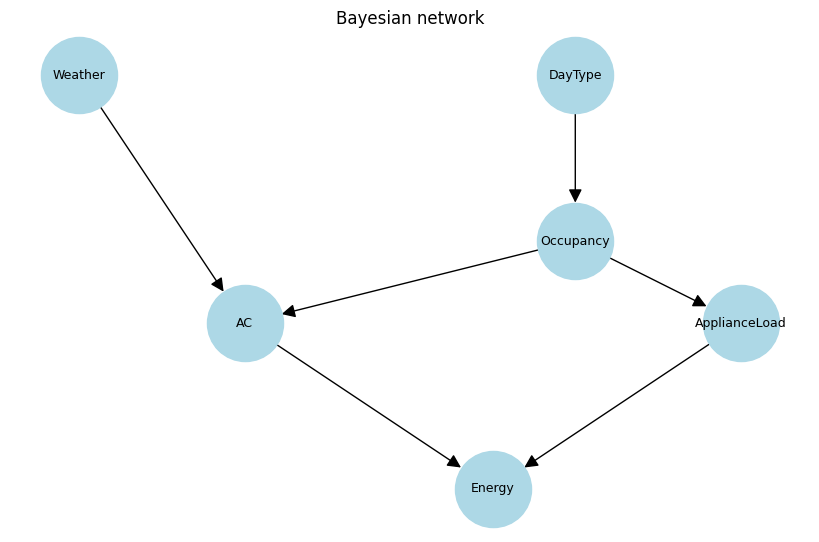

In [6]:
g = nx.DiGraph(edges)
pos = {"Weather": (0, 2), "DayType": (3, 2), "Occupancy": (3, 1),
       "AC": (1, 0.5), "ApplianceLoad": (4, 0.5), "Energy": (2.5, -0.5)}
plt.figure(figsize=(8, 5))
nx.draw(g, pos, with_labels=True, node_color="lightblue", node_size=3000, font_size=9, arrowsize=20)
plt.title("Bayesian network")
plt.savefig("network.png")
plt.show()

Now the queries. I made a small function that gives P(var = state | evidence) so I don't have to repeat the inference code each time.

In [7]:
def prob(m, var, state, evidence={}):
    inf = VariableElimination(m)
    res = inf.query([var], evidence=evidence, show_progress=False)
    return res.values[res.state_names[var].index(state)]

def allQueries(m):
    q = []
    q.append(prob(m, "Energy", "High"))
    q.append(prob(m, "Energy", "High", {"Weather": "Hot"}))
    q.append(prob(m, "Energy", "High", {"DayType": "Weekend"}))
    q.append(prob(m, "Energy", "High", {"Weather": "Cold", "Occupancy": "High"}))
    q.append(prob(m, "Weather", "Hot", {"Energy": "High"}))
    q.append(prob(m, "AC", "On", {"Energy": "High"}))
    q.append(prob(m, "AC", "On", {"Energy": "High", "ApplianceLoad": "Heavy"}))
    return q

qnames = ["Q1", "Q2", "Q3", "Q4", "Q5", "Q6", "Q7"]
expertQ = allQueries(model)
for n, v in zip(qnames, expertQ):
    print(n, round(v, 4))

Q1 0.5806
Q2 0.7063
Q3 0.6402
Q4 0.4843
Q5 0.6082
Q6 0.6929
Q7 0.6499


Q6 vs Q7

Q6 is P(AC=On | E=High) = 0.6929 and Q7 is P(AC=On | E=High, Load=Heavy) = 0.6499, so the probability of AC being on goes down a bit once we know the load is heavy.

This is explaining away. High energy can come from the AC being on or from a heavy appliance load. If we only know energy is high, then both causes become more likely. But if we are also told the load is heavy, that already explains the high energy by itself, so there is less need for the AC to be on. AC and load are not connected directly, they are two parents of Energy, so observing Energy makes them dependent on each other.

Q1 by hand

Energy depends on AC and Load, and both of these depend on Occupancy, so I first find P(Occupancy) and then work out P(AC) and P(Load) for each occupancy value.

P(O=High) = 0.7 x 0.45 + 0.3 x 0.8 = 0.315 + 0.24 = 0.555
P(O=Low) = 0.445

P(AC=On | O=High) = 0.5 x 0.9 + 0.3 x 0.4 + 0.2 x 0.1 = 0.45 + 0.12 + 0.02 = 0.59
P(AC=On | O=Low) = 0.5 x 0.6 + 0.3 x 0.15 + 0.2 x 0.05 = 0.3 + 0.045 + 0.01 = 0.355

For O = High: P(AC=On) = 0.59, P(AC=Off) = 0.41, P(Heavy) = 0.75, P(Light) = 0.25

P(E=High | O=High) = 0.59 x 0.75 x 0.92 + 0.59 x 0.25 x 0.68 + 0.41 x 0.75 x 0.55 + 0.41 x 0.25 x 0.12
= 0.4071 + 0.1003 + 0.169125 + 0.0123 = 0.688825

For O = Low: P(AC=On) = 0.355, P(AC=Off) = 0.645, P(Heavy) = 0.35, P(Light) = 0.65

P(E=High | O=Low) = 0.355 x 0.35 x 0.92 + 0.355 x 0.65 x 0.68 + 0.645 x 0.35 x 0.55 + 0.645 x 0.65 x 0.12
= 0.11431 + 0.15691 + 0.1241625 + 0.05031 = 0.4456925

P(E=High) = 0.555 x 0.688825 + 0.445 x 0.4456925
= 0.382298 + 0.198333 = 0.580631

Checking it with code by summing over all the variables:

In [8]:
pW = {"Hot": 0.5, "Mild": 0.3, "Cold": 0.2}
pD = {"Weekday": 0.7, "Weekend": 0.3}
pOHigh = {"Weekday": 0.45, "Weekend": 0.80}
pAOn = {("Hot", "High"): 0.9, ("Hot", "Low"): 0.6, ("Mild", "High"): 0.4, ("Mild", "Low"): 0.15, ("Cold", "High"): 0.1, ("Cold", "Low"): 0.05}
pHeavy = {"High": 0.75, "Low": 0.35}
pEHigh = {("On", "Heavy"): 0.92, ("On", "Light"): 0.68,
          ("Off", "Heavy"): 0.55, ("Off", "Light"): 0.12}

total = 0
for w in pW:
    for d in pD:
        for o in ["High", "Low"]:
            po = pOHigh[d] if o == "High" else 1 - pOHigh[d]
            for a in ["On", "Off"]:
                pa = pAOn[(w, o)] if a == "On" else 1 - pAOn[(w, o)]
                for l in ["Heavy", "Light"]:
                    pl = pHeavy[o] if l == "Heavy" else 1 - pHeavy[o]
                    total = total + pW[w] * pD[d] * po * pa * pl * pEHigh[(a, l)]

print("by summation:", total)
print("from pgmpy:", expertQ[0])

by summation: 0.5806310375
from pgmpy: 0.5806310375


## Part B: Conditional independence

1. Weather and DayType (nothing observed). The only path is Weather -> AC <- Occupancy <- DayType. AC is a collider and it is not observed (neither is Energy, its child), so the path is blocked. They are independent.

2. Weather and DayType given Energy. Now Energy is observed, and Energy is a descendant of the collider AC, so the path Weather -> AC <- Occupancy <- DayType opens up. They are NOT independent.

3. Weather and ApplianceLoad given Occupancy. One path is Weather -> AC <- Occupancy -> ApplianceLoad, which is blocked because Occupancy is observed (and AC is an unobserved collider anyway). The other path is Weather -> AC -> Energy <- ApplianceLoad, which is blocked because Energy is an unobserved collider. They are independent.

In [9]:
print(model.is_dconnected("Weather", "DayType", observed=[]))
print(model.is_dconnected("Weather", "DayType", observed=["Energy"]))
print(model.is_dconnected("Weather", "ApplianceLoad", observed=["Occupancy"]))

False
True
False


In [10]:
print(prob(model, "Weather", "Hot"))
print(prob(model, "Weather", "Hot", {"DayType": "Weekend"}))

print(prob(model, "Weather", "Hot", {"Energy": "High"}))
print(prob(model, "Weather", "Hot", {"Energy": "High", "DayType": "Weekend"}))

print(prob(model, "Weather", "Hot", {"Occupancy": "High"}))
print(prob(model, "Weather", "Hot", {"Occupancy": "High", "ApplianceLoad": "Heavy"}))

0.5
0.5
0.6081880784748782
0.5997514833289987
0.5
0.5


For 1 and 3 the numbers are the same (0.5 and 0.5), so they are independent. For 2, P(W=Hot | E=High) = 0.6082 but with DayType = Weekend it becomes 0.5998, so they are different and the variables are dependent given Energy.

## Part C: Synthetic data

I sample the nodes in topological order (Weather, DayType, Occupancy, AC, ApplianceLoad, Energy). Each node is sampled using the values already picked for its parents.

In [11]:
seed = 42
rng = np.random.default_rng(seed)
def pick(options, probs):
    u = rng.random()
    cum = 0
    for o, p in zip(options, probs):
        cum = cum + p
        if u < cum:
            return o
    return options[-1]

def oneSample():
    w = pick(["Hot", "Mild", "Cold"], [pW["Hot"], pW["Mild"], pW["Cold"]])
    d = pick(["Weekday", "Weekend"], [pD["Weekday"], pD["Weekend"]])
    o = pick(["High", "Low"], [pOHigh[d], 1 - pOHigh[d]])
    a = pick(["On", "Off"], [pAOn[(w, o)], 1 - pAOn[(w, o)]])
    l = pick(["Heavy", "Light"], [pHeavy[o], 1 - pHeavy[o]])
    e = pick(["High", "Low"], [pEHigh[(a, l)], 1 - pEHigh[(a, l)]])
    return [w, d, o, a, l, e]

cols = ["Weather", "DayType", "Occupancy", "AC", "ApplianceLoad", "Energy"]
sizes = [500, 5000, 20000]
data = {}
for n in sizes:
    data[n] = pd.DataFrame([oneSample() for i in range(n)], columns=cols)

print("seed =", seed)
data[500].head()

seed = 42


,Weather,DayType,Occupancy,AC,ApplianceLoad,Energy
0,Mild,Weekday,Low,Off,Heavy,Low
1,Mild,Weekend,High,Off,Heavy,Low
2,Mild,Weekend,High,On,Heavy,High
3,Cold,Weekday,Low,Off,Light,Low
4,Mild,Weekday,Low,On,Heavy,High


In [12]:
for n in sizes:
    print("n =", n)
    print(data[n]["Weather"].value_counts(normalize=True))
    print(pd.crosstab(data[n]["Weather"], data[n]["Occupancy"]))
    print()

n = 500
Weather
Hot     0.510
Mild    0.286
Cold    0.204
Name: proportion, dtype: float64
Occupancy  High  Low
Weather             
Cold         51   51
Hot         155  100
Mild         75   68

n = 5000
Weather
Hot     0.4974
Mild    0.3052
Cold    0.1974
Name: proportion, dtype: float64
Occupancy  High   Low
Weather              
Cold        570   417
Hot        1393  1094
Mild        841   685

n = 20000
Weather
Hot     0.4990
Mild    0.3037
Cold    0.1973
Name: proportion, dtype: float64
Occupancy  High   Low
Weather              
Cold       2180  1766
Hot        5530  4450
Mild       3427  2647



## Part D: Learning the parameters

Same structure as the expert network. I learn the CPTs with MLE and with the Bayesian estimator (BDeu, equivalent sample size 10), for all three datasets.

In [13]:
mleModels = {}
bayesModels = {}

for n in sizes:
    m1 = BayesNet(edges)
    est1 = MaximumLikelihoodEstimator(m1, data[n], state_names=states)
    m1.add_cpds(*est1.get_parameters())
    mleModels[n] = m1

    m2 = BayesNet(edges)
    est2 = BayesianEstimator(m2, data[n], state_names=states)
    m2.add_cpds(*est2.get_parameters(prior_type="BDeu", equivalent_sample_size=10))
    bayesModels[n] = m2

print("done")

done


AC CPT (only the AC = On row) for the expert model and the learned models.

In [14]:
def acOn(m):
    c = m.get_cpds("AC")
    ax = {v: i for i, v in enumerate(c.variables)}
    out = []
    for w in states["Weather"]:
        for o in states["Occupancy"]:
            idx = [0, 0, 0]
            idx[ax["AC"]] = c.state_names["AC"].index("On")
            idx[ax["Weather"]] = c.state_names["Weather"].index(w)
            idx[ax["Occupancy"]] = c.state_names["Occupancy"].index(o)
            out.append(c.values[tuple(idx)])
    return out

rows = [(w, o) for w in states["Weather"] for o in states["Occupancy"]]

for n in sizes:
    t = pd.DataFrame({"Expert": acOn(model), "MLE": acOn(mleModels[n]),
                      "Bayesian": acOn(bayesModels[n])}, index=rows)
    print("P(AC=On | Weather, Occupancy), n =", n)
    print(t.round(4))
    print()

P(AC=On | Weather, Occupancy), n = 500
              Expert     MLE  Bayesian
(Hot, High)     0.90  0.8516    0.8479
(Hot, Low)      0.60  0.6600    0.6574
(Mild, High)    0.40  0.3600    0.3630
(Mild, Low)     0.15  0.1765    0.1842
(Cold, High)    0.10  0.0980    0.1108
(Cold, Low)     0.05  0.0196    0.0348

P(AC=On | Weather, Occupancy), n = 5000
              Expert     MLE  Bayesian
(Hot, High)     0.90  0.8995    0.8990
(Hot, Low)      0.60  0.6133    0.6132
(Mild, High)    0.40  0.3995    0.3997
(Mild, Low)     0.15  0.1416    0.1425
(Cold, High)    0.10  0.1018    0.1029
(Cold, Low)     0.05  0.0600    0.0617

P(AC=On | Weather, Occupancy), n = 20000
              Expert     MLE  Bayesian
(Hot, High)     0.90  0.9069    0.9067
(Hot, Low)      0.60  0.5946    0.5946
(Mild, High)    0.40  0.3933    0.3934
(Mild, Low)     0.15  0.1511    0.1513
(Cold, High)    0.10  0.1092    0.1095
(Cold, Low)     0.05  0.0532    0.0536



## Part E: Comparison

In [15]:
tables = {}
for n in sizes:
    mq = np.array(allQueries(mleModels[n]))
    bq = np.array(allQueries(bayesModels[n]))
    eq = np.array(expertQ)
    t = pd.DataFrame({"Expert": eq, "MLE": mq, "Bayesian": bq,
                      "|Diff| MLE": abs(mq - eq), "|Diff| Bayesian": abs(bq - eq)},
                     index=qnames)
    tables[n] = t
    print("n =", n)
    print(t.round(4))
    print()

n = 500
    Expert     MLE  Bayesian  |Diff| MLE  |Diff| Bayesian
Q1  0.5806  0.5570    0.5559      0.0237           0.0247
Q2  0.7063  0.7050    0.6991      0.0013           0.0072
Q3  0.6402  0.6092    0.6046      0.0310           0.0356
Q4  0.4843  0.4203    0.4268      0.0639           0.0575
Q5  0.6082  0.6455    0.6370      0.0373           0.0288
Q6  0.6929  0.7280    0.7236      0.0351           0.0307
Q7  0.6499  0.6584    0.6560      0.0085           0.0061

n = 5000
    Expert     MLE  Bayesian  |Diff| MLE  |Diff| Bayesian
Q1  0.5806  0.5815    0.5813      0.0008           0.0007
Q2  0.7063  0.7033    0.7027      0.0030           0.0035
Q3  0.6402  0.6428    0.6422      0.0026           0.0020
Q4  0.4843  0.4894    0.4897      0.0051           0.0055
Q5  0.6082  0.6016    0.6009      0.0066           0.0073
Q6  0.6929  0.6870    0.6866      0.0059           0.0062
Q7  0.6499  0.6513    0.6510      0.0014           0.0011

n = 20000
    Expert     MLE  Bayesian  |Diff| MLE  |

MLE: [0.0287 0.0036 0.0019]
Bayesian: [0.0272 0.0038 0.002 ]


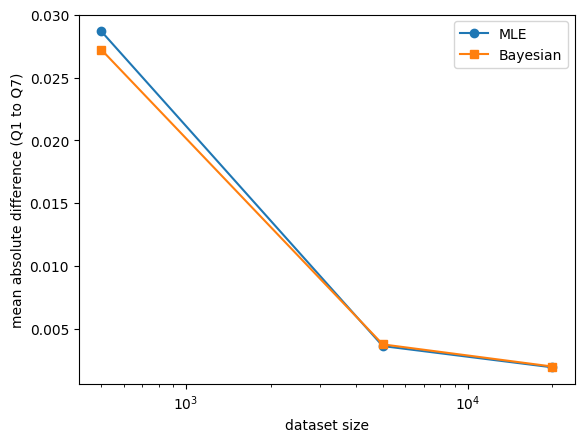

In [16]:
meanMLE = [tables[n]["|Diff| MLE"].mean() for n in sizes]
meanBayes = [tables[n]["|Diff| Bayesian"].mean() for n in sizes]
print("MLE:", np.round(meanMLE, 4))
print("Bayesian:", np.round(meanBayes, 4))

plt.plot(sizes, meanMLE, marker="o", label="MLE")
plt.plot(sizes, meanBayes, marker="s", label="Bayesian")
plt.xscale("log")
plt.xlabel("dataset size")
plt.ylabel("mean absolute difference (Q1 to Q7)")
plt.legend()
plt.savefig("error plot.png")
plt.show()

In [17]:
print(tables[500]["|Diff| MLE"].idxmax(), tables[500]["|Diff| Bayesian"].idxmax())
d = data[500]
print("Weather=Hot:", (d.Weather == "Hot").sum())
print("DayType=Weekend:", (d.DayType == "Weekend").sum())
print("Cold and High occupancy:", ((d.Weather == "Cold") & (d.Occupancy == "High")).sum())
print("Energy=High:", (d.Energy == "High").sum())
print("Energy=High and Heavy load:", ((d.Energy == "High") & (d.ApplianceLoad == "Heavy")).sum())

Q4 Q4
Weather=Hot: 255
DayType=Weekend: 157
Cold and High occupancy: 51
Energy=High: 280
Energy=High and Heavy load: 198


The largest error for 500 samples is in Q4, P(E=High | Weather=Cold, Occupancy=High). Both estimators have about 0.06 error here (0.064 for MLE, 0.058 for Bayesian). The reason is that the evidence for Q4 is rare. Only 51 of the 500 rows have Cold weather and High occupancy, and the AC probability for this case is learned from only those rows (about 5 of them have the AC on), so a couple of rows more or less change the estimate a lot. The other queries have more rows behind them, e.g. 255 rows for Weather=Hot, and their errors are much smaller.

For the small dataset the Bayesian estimator is a little better, the mean error is 0.0272 against 0.0287 for MLE. The difference is small though, and MLE is actually better in Q1, Q2 and Q3, so it is not a big win. The reason it helps is that MLE just uses raw counts, so with few rows it can give extreme values (for example P(AC=On | Cold, Low) came out as 0.0196 in MLE while the true value is 0.05, and the Bayesian one gave 0.0348). If a parent combination never appeared in the data, MLE would not have an estimate for it at all. The BDeu prior adds some pseudo counts that pull the sparse estimates towards a uniform value. Since the equivalent sample size is only 10, the effect on 500 rows is not very large.

When the data increases to 5000 and 20000, the pseudo counts do not matter anymore and the two estimators give almost the same results (0.0036 vs 0.0037 and 0.0019 vs 0.0020). Both errors go down as there is more data.